In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

print("Libraries Imported Successfully!")

Libraries Imported Successfully!


In [2]:
df = pd.read_csv("../data/processed/customer_churn_clean.csv")

df.head()

,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,9.0,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,9.0,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,50005,1,0.0,Phone,1,12.0,CC,Male,3.0,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60


In [3]:
print("Shape:", df.shape)
print("\nData Types\n")
print(df.dtypes)

Shape: (5630, 20)

Data Types

CustomerID                       int64
Churn                            int64
Tenure                         float64
PreferredLoginDevice               str
CityTier                         int64
WarehouseToHome                float64
PreferredPaymentMode               str
Gender                             str
HourSpendOnApp                 float64
NumberOfDeviceRegistered         int64
PreferedOrderCat                   str
SatisfactionScore                int64
MaritalStatus                      str
NumberOfAddress                  int64
Complain                         int64
OrderAmountHikeFromlastYear    float64
CouponUsed                     float64
OrderCount                     float64
DaySinceLastOrder              float64
CashbackAmount                 float64
dtype: object


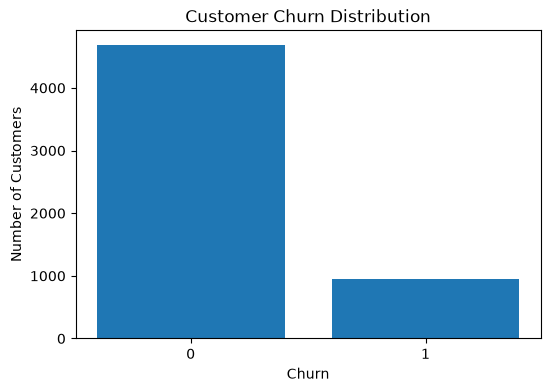

Churn
0    83.16
1    16.84
Name: proportion, dtype: float64

In [5]:
##churn distribution
churn_counts = df["Churn"].value_counts()

plt.figure(figsize=(6,4))
plt.bar(churn_counts.index.astype(str), churn_counts.values)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()
(df["Churn"].value_counts(normalize=True)*100).round(2)


In [6]:
(df["Churn"].value_counts(normalize=True)*100).round(2)

Churn
0    83.16
1    16.84
Name: proportion, dtype: float64

In [7]:
##numerical feature distribution
numerical_cols = [
    "Tenure",
    "WarehouseToHome",
    "HourSpendOnApp",
    "NumberOfDeviceRegistered",
    "SatisfactionScore",
    "NumberOfAddress",
    "OrderAmountHikeFromlastYear",
    "CouponUsed",
    "OrderCount",
    "DaySinceLastOrder",
    "CashbackAmount"
]

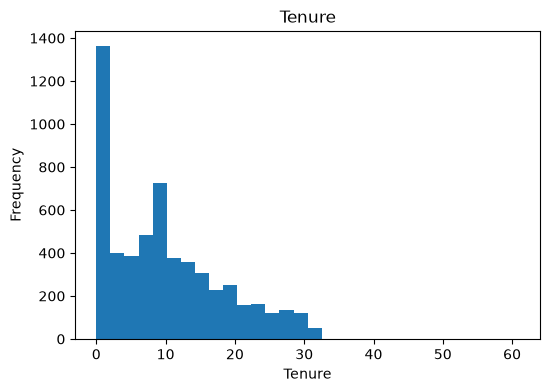

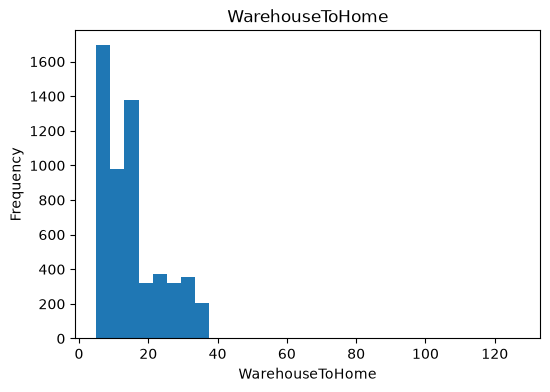

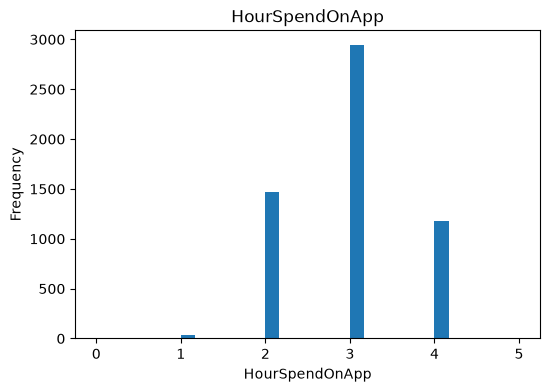

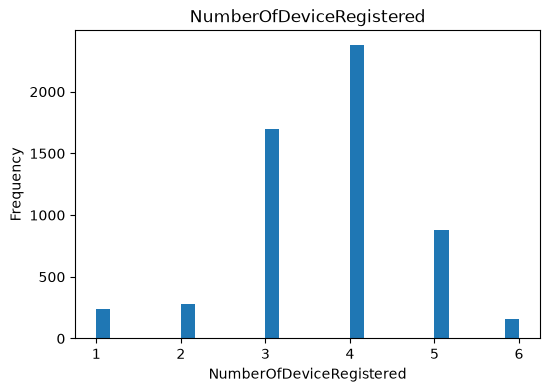

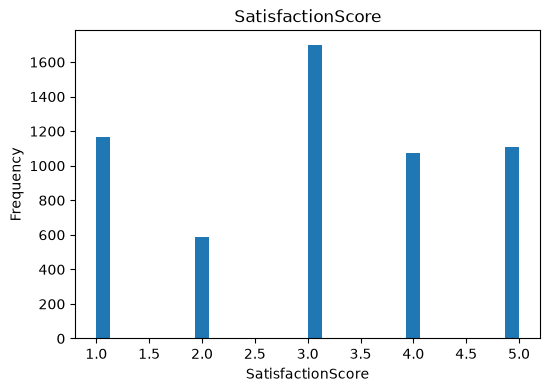

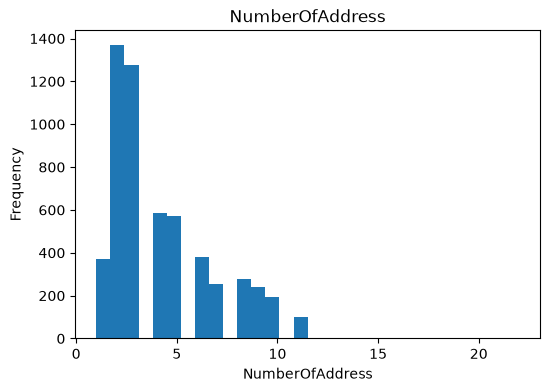

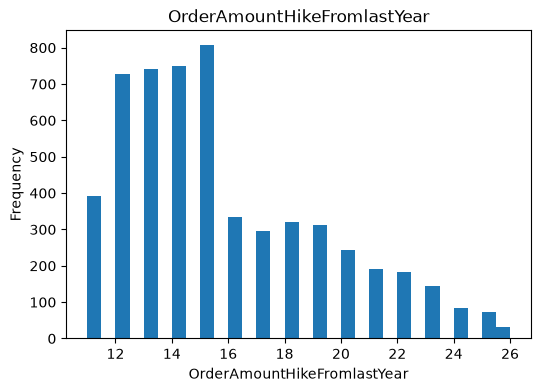

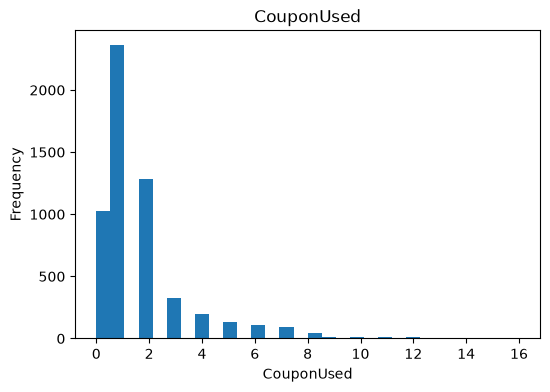

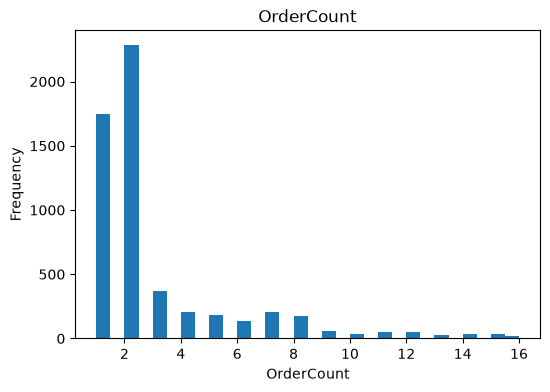

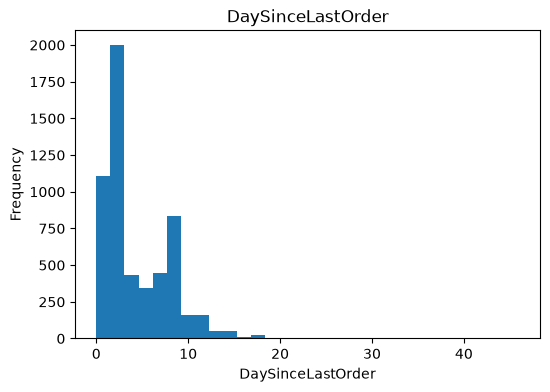

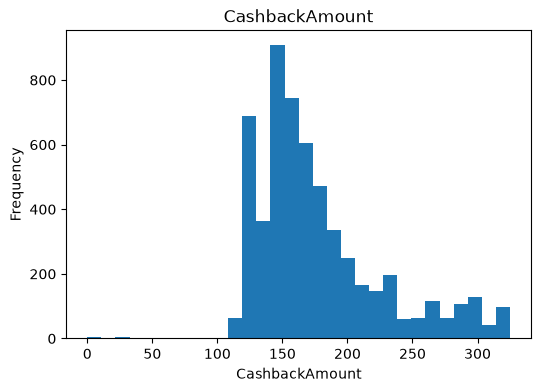

In [8]:
for col in numerical_cols:

    plt.figure(figsize=(6,4))

    plt.hist(df[col], bins=30)

    plt.title(col)

    plt.xlabel(col)

    plt.ylabel("Frequency")

    plt.show()

In [9]:
##categorical features
categorical_cols = [
    "PreferredLoginDevice",
    "CityTier",
    "PreferredPaymentMode",
    "Gender",
    "PreferedOrderCat",
    "MaritalStatus",
    "Complain"
]

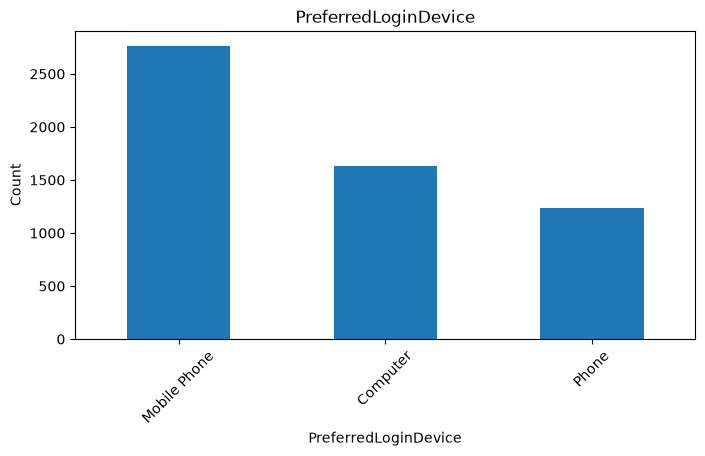

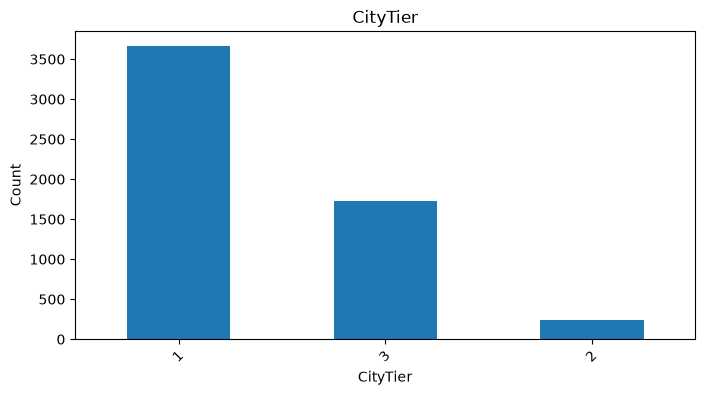

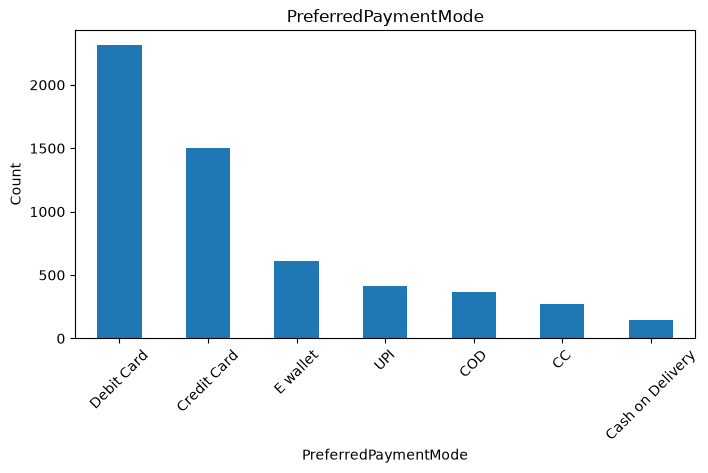

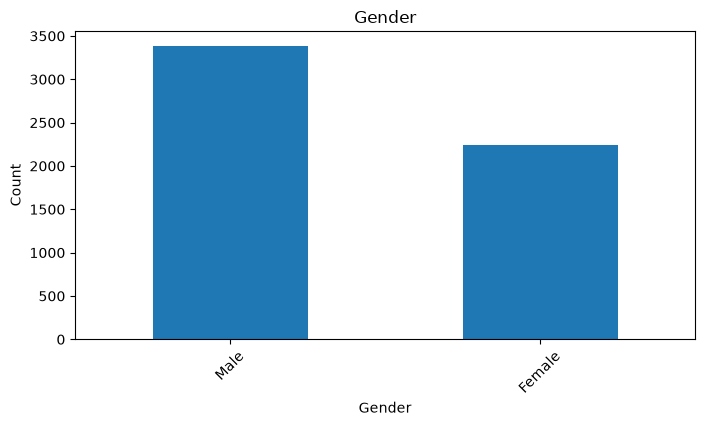

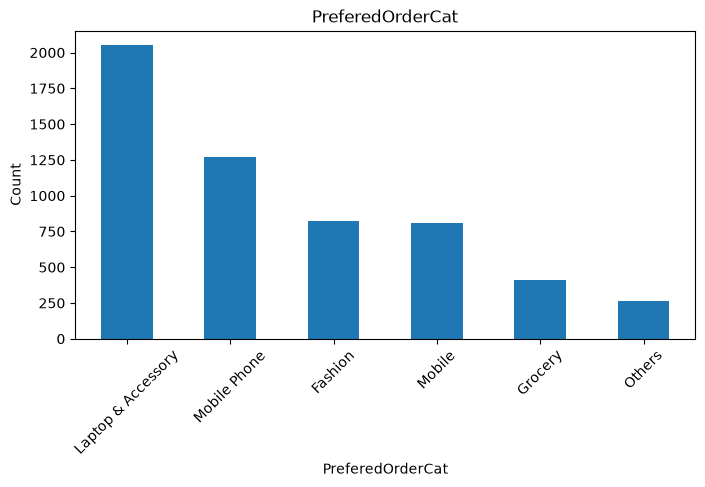

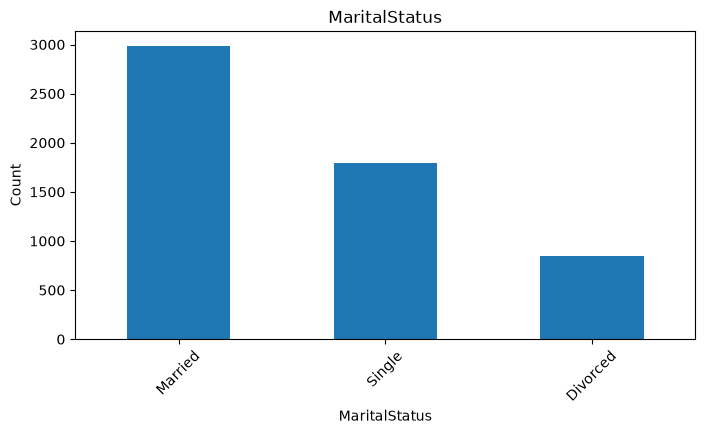

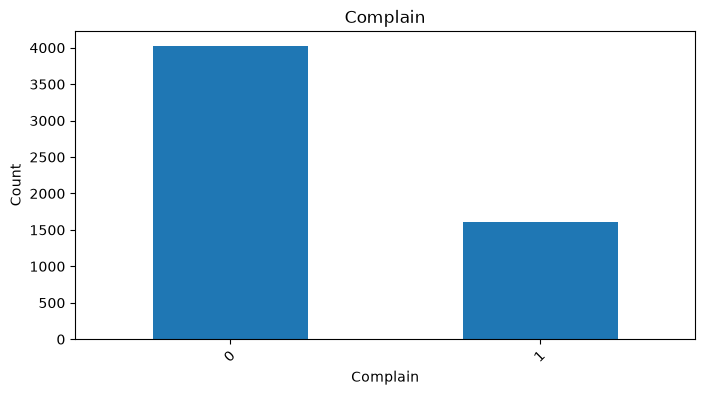

In [ ]:
for col in categorical_cols:

    plt.figure(figsize=(8,4))
    df[col].value_counts().plot(kind="bar")
    plt.title(col)
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=45)
    plt.show()

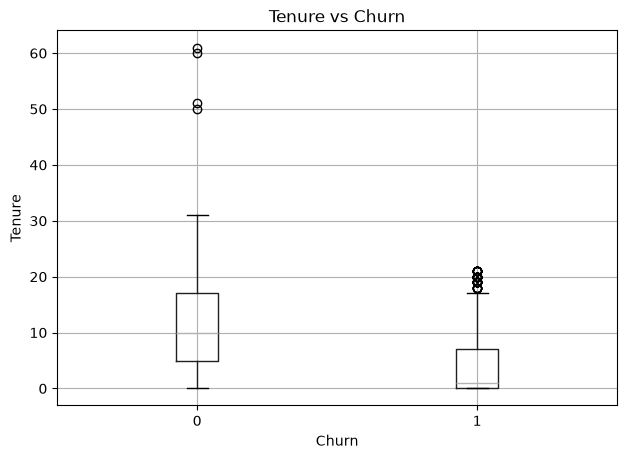

In [11]:
##tenure vs churn
df.boxplot(
    column="Tenure",
    by="Churn",
    figsize=(7,5)
)

plt.title("Tenure vs Churn")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Tenure")

plt.show()

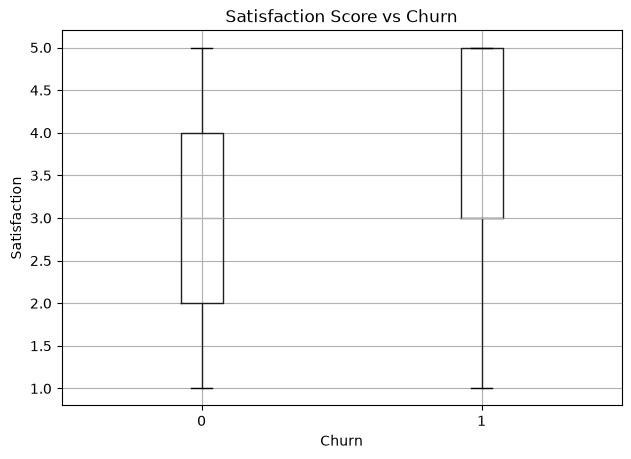

In [12]:
##satisfaction vs churn
df.boxplot(
    column="SatisfactionScore",
    by="Churn",
    figsize=(7,5)
)

plt.title("Satisfaction Score vs Churn")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Satisfaction")

plt.show()

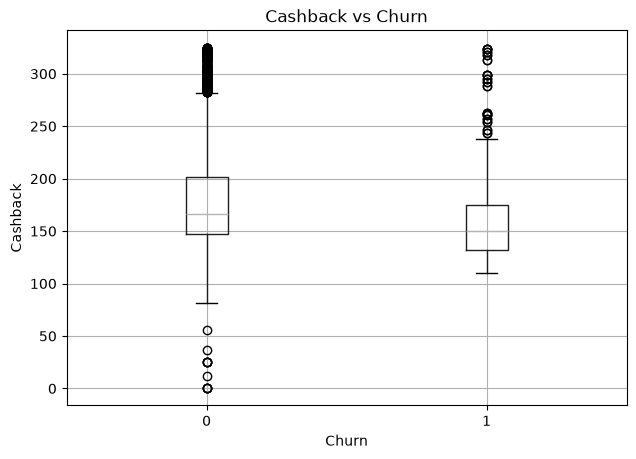

In [13]:
##cashback vs churn
df.boxplot(
    column="CashbackAmount",
    by="Churn",
    figsize=(7,5)
)

plt.title("Cashback vs Churn")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Cashback")

plt.show()

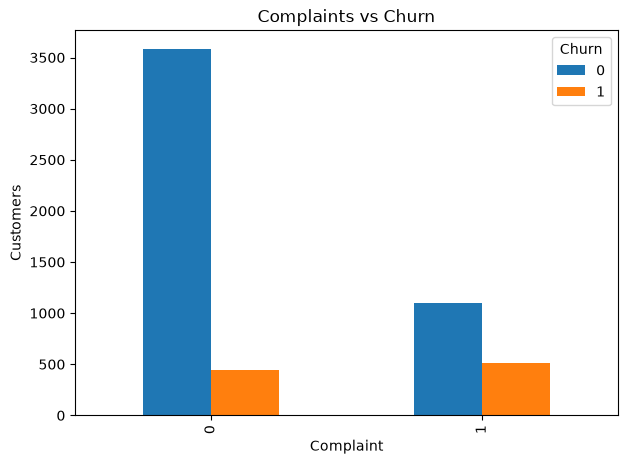

In [ ]:
##complaints vs churn
complaint = pd.crosstab(
    df["Complain"],
    df["Churn"]
)

complaint.plot(kind="bar", figsize=(7,5))
plt.title("Complaints vs Churn")
plt.xlabel("Complaint")
plt.ylabel("Customers")
plt.show()

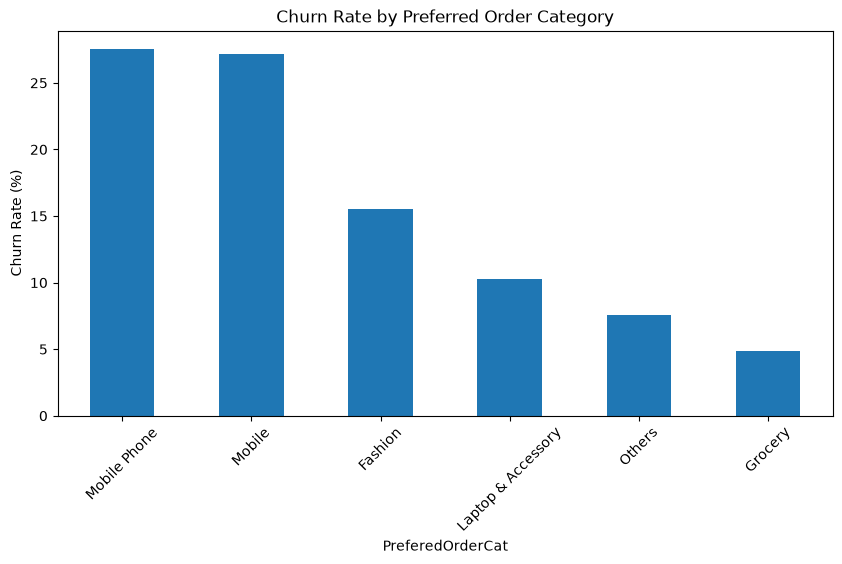

In [ ]:
##preferred category vs churn
category_churn = (
    df.groupby("PreferedOrderCat")["Churn"]
      .mean()
      * 100
).sort_values(ascending=False)

category_churn.plot(kind="bar", figsize=(10,5))
plt.ylabel("Churn Rate (%)")
plt.title("Churn Rate by Preferred Order Category")
plt.xticks(rotation=45)
plt.show()

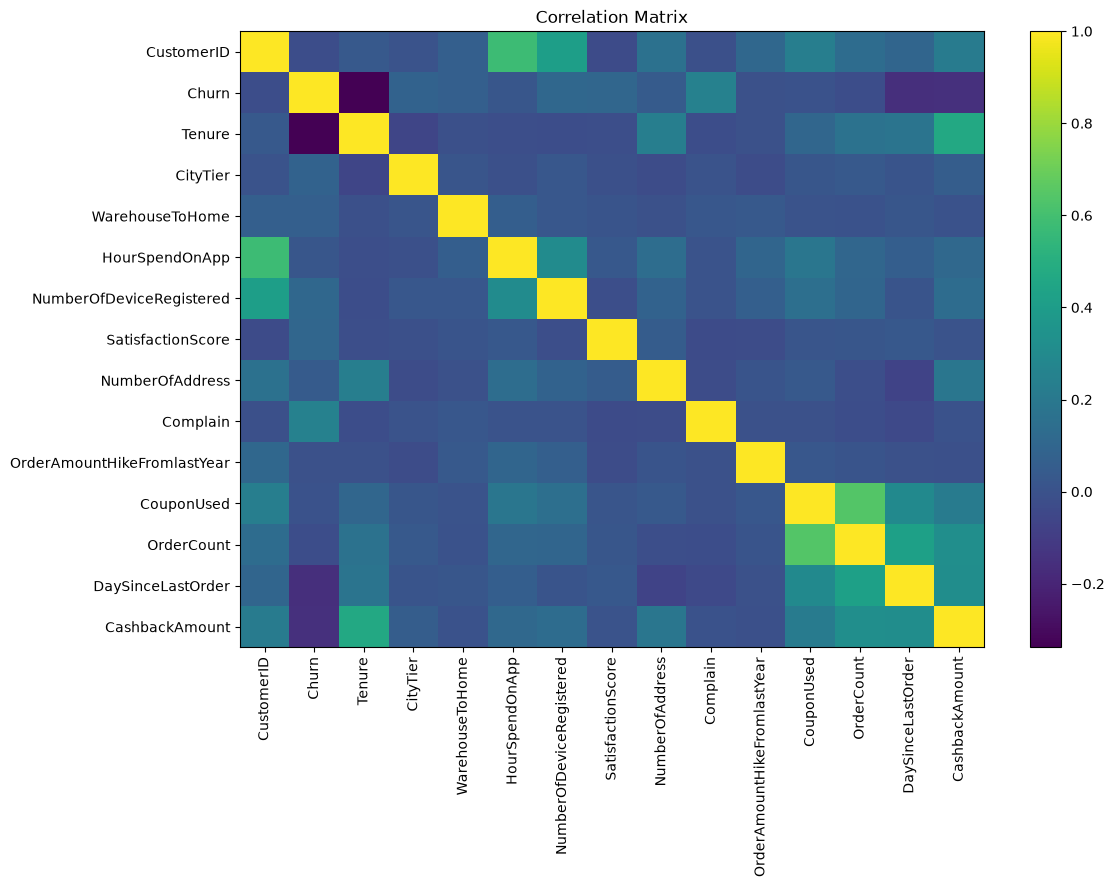

In [ ]:
##correlation matrix
correlation = df.select_dtypes(include=np.number).corr()

plt.figure(figsize=(12,8))
plt.imshow(correlation, aspect="auto")
plt.colorbar()
plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Correlation Matrix")
plt.show()

In [17]:
##correlation with churn
corr = (
    df.select_dtypes(include=np.number)
      .corr()["Churn"]
      .sort_values(ascending=False)
)

corr

Churn                          1.000000
Complain                       0.250188
NumberOfDeviceRegistered       0.107939
SatisfactionScore              0.105481
CityTier                       0.084703
WarehouseToHome                0.069544
NumberOfAddress                0.043931
HourSpendOnApp                 0.018816
CouponUsed                    -0.001430
OrderAmountHikeFromlastYear   -0.007075
CustomerID                    -0.019083
OrderCount                    -0.024038
CashbackAmount                -0.154118
DaySinceLastOrder             -0.155871
Tenure                        -0.337831
Name: Churn, dtype: float64

In [18]:
df["Complain"].value_counts()

Complain
0    4026
1    1604
Name: count, dtype: int64

In [19]:
df["Churn"].value_counts()

Churn
0    4682
1     948
Name: count, dtype: int64